<a href="https://colab.research.google.com/github/YOUR_GITHUB_USERNAME/Deep-Learning/blob/main/Exp8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Experiment 8: Two-Layer Neural Network with Backpropagation

**Category**: CO2 – Neural Networks and CNNs  
**Objective**: Implement full forward pass, analytical backpropagation with gradient updates, and non-linear decision boundary visualization in NumPy.


### Task 1: Construct Non-Linear Dataset (Moons Classification)


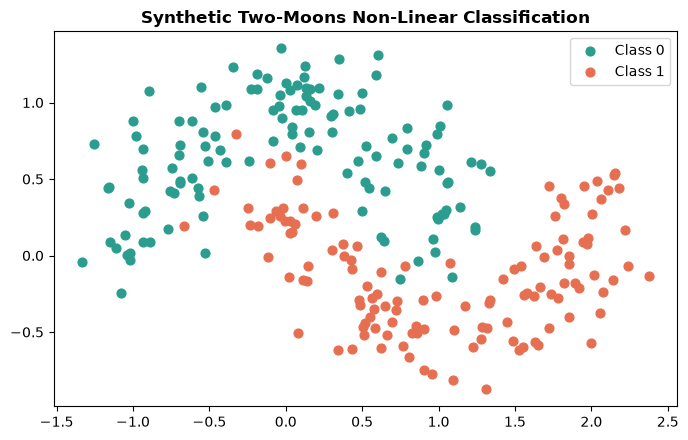

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons

np.random.seed(101)
X_moons, y_moons = make_moons(n_samples=250, noise=0.20, random_state=42)
y_moons = y_moons.reshape(-1, 1)

plt.figure(figsize=(7, 4.5))
plt.scatter(X_moons[y_moons.ravel() == 0, 0], X_moons[y_moons.ravel() == 0, 1], color='#2a9d8f', s=40, label='Class 0')
plt.scatter(X_moons[y_moons.ravel() == 1, 0], X_moons[y_moons.ravel() == 1, 1], color='#e76f51', s=40, label='Class 1')
plt.title("Synthetic Two-Moons Non-Linear Classification", fontweight='bold')
plt.legend()
plt.tight_layout()
plt.show()


### Task 2: Implement Two-Layer Neural Network with Pure NumPy Backprop


In [2]:
def sigmoid(z):
    return 1.0 / (1.0 + np.exp(-np.clip(z, -15, 15)))

def sigmoid_deriv(a):
    return a * (1.0 - a)

# Initialize network parameters: 2 -> 8 -> 1
hidden_units = 8
W1 = np.random.randn(2, hidden_units) * np.sqrt(2.0 / 2)
b1 = np.zeros((1, hidden_units))
W2 = np.random.randn(hidden_units, 1) * np.sqrt(2.0 / hidden_units)
b2 = np.zeros((1, 1))

lr = 0.15
epochs = 1200
loss_log = []

for epoch in range(epochs):
    # Forward Pass
    Z1 = np.dot(X_moons, W1) + b1
    A1 = np.tanh(Z1)  # Hidden activation
    Z2 = np.dot(A1, W2) + b2
    A2 = sigmoid(Z2)  # Output activation

    # Binary Cross-Entropy Loss
    loss = -np.mean(y_moons * np.log(A2 + 1e-12) + (1.0 - y_moons) * np.log(1.0 - A2 + 1e-12))
    loss_log.append(loss)

    # Backpropagation
    dZ2 = (A2 - y_moons) / len(X_moons)
    dW2 = np.dot(A1.T, dZ2)
    db2 = np.sum(dZ2, axis=0, keepdims=True)

    dA1 = np.dot(dZ2, W2.T)
    dZ1 = dA1 * (1.0 - np.square(A1)) # tanh derivative
    dW1 = np.dot(X_moons.T, dZ1)
    db1 = np.sum(dZ1, axis=0, keepdims=True)

    # Gradient Descent parameter updates
    W2 -= lr * dW2
    b2 -= lr * db2
    W1 -= lr * dW1
    b1 -= lr * db1

preds_final = (A2 >= 0.5).astype(int)
acc = np.mean(preds_final == y_moons) * 100
print(f"Final Epoch Loss: {loss_log[-1]:.4f} | Training Accuracy: {acc:.2f}%")


Final Epoch Loss: 0.1354 | Training Accuracy: 95.20%


### Task 3: Training Loss History and Non-Linear Decision Boundary


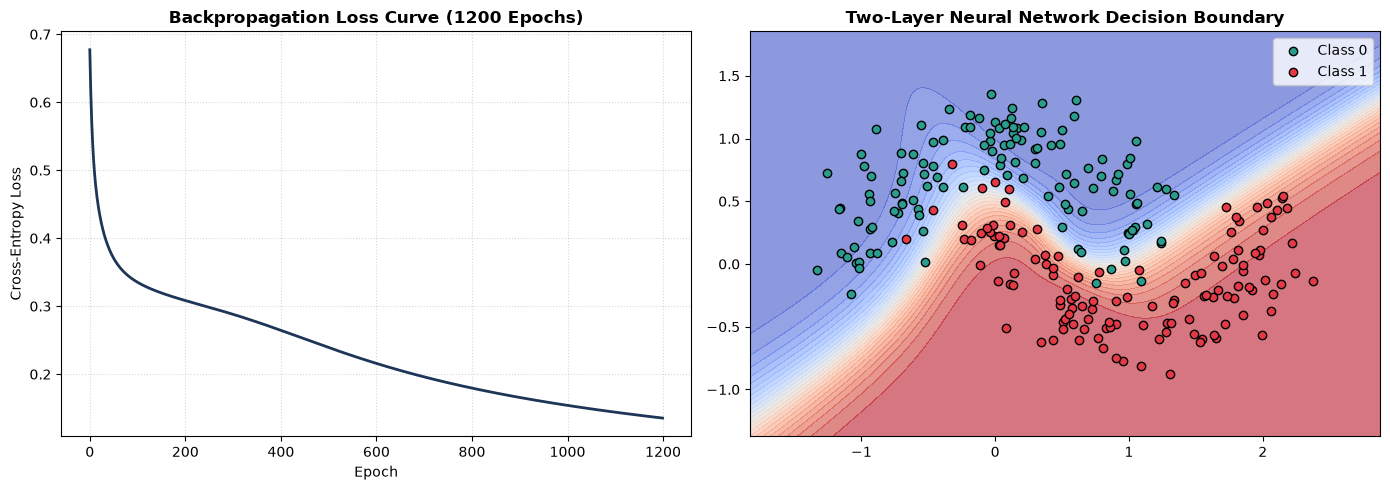

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Loss curve
axes[0].plot(loss_log, color='#1d3557', lw=2)
axes[0].set_title("Backpropagation Loss Curve (1200 Epochs)", fontweight='bold')
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Cross-Entropy Loss")
axes[0].grid(True, linestyle=':', alpha=0.5)

# 2. Decision boundary mesh
x_min, x_max = X_moons[:, 0].min() - 0.5, X_moons[:, 0].max() + 0.5
y_min, y_max = X_moons[:, 1].min() - 0.5, X_moons[:, 1].max() + 0.5
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 200), np.linspace(y_min, y_max, 200))
grid_points = np.c_[xx.ravel(), yy.ravel()]

# Forward pass on grid
Z1_grid = np.tanh(np.dot(grid_points, W1) + b1)
prob_grid = sigmoid(np.dot(Z1_grid, W2) + b2).reshape(xx.shape)

axes[1].contourf(xx, yy, prob_grid, levels=25, cmap='coolwarm', alpha=0.6)
axes[1].scatter(X_moons[y_moons.ravel() == 0, 0], X_moons[y_moons.ravel() == 0, 1], color='#2a9d8f', edgecolors='k', label='Class 0')
axes[1].scatter(X_moons[y_moons.ravel() == 1, 0], X_moons[y_moons.ravel() == 1, 1], color='#e63946', edgecolors='k', label='Class 1')
axes[1].set_title("Two-Layer Neural Network Decision Boundary", fontweight='bold')
axes[1].legend()

plt.tight_layout()
plt.show()
